In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv('/home/manto/projects/telcom-revenue-at-risk-predictor/data/raw/telco_churn_with_all_feedback.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,PromptInput,CustomerFeedback
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,Write a realistic customer feedback based on t...,I have been using the DSL internet service fro...
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.5,No,Write a realistic customer feedback based on t...,I have been a customer with this company for o...
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Write a realistic customer feedback based on t...,I recently signed up for DSL internet service ...
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Write a realistic customer feedback based on t...,I have been a loyal customer with this company...
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Write a realistic customer feedback based on t...,I recently switched to this fiber optic intern...


In [3]:
df.shape

(7043, 23)

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [9]:
# Shape
df.shape

(7043, 23)

In [10]:
# Columns
df.columns.to_list()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn',
 'PromptInput',
 'CustomerFeedback']

In [17]:
# info

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [ ]:
# checking for null values
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
PromptInput         0
CustomerFeedback    0
dtype: int64

In [23]:
# checking for duplicates
print(df.duplicated().sum())

0


In [24]:
# checking duplicates for customer id
df['customerID'].duplicated().sum()

np.int64(0)

In [25]:
# checking the distinct values for the target variable - churn
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [ ]:
# Variations of churn in percentages
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [28]:
# describe
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [30]:
# analyze SeniorCitizen column
df['SeniorCitizen'].value_counts(normalize=True) * 100

SeniorCitizen
0    83.785319
1    16.214681
Name: proportion, dtype: float64

In [32]:
# analyze tenure col
df['tenure'].value_counts(normalize=False)

tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64

In [33]:
df['tenure'].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [34]:
# mean = 32.371, median = 29.0, mode = 1.0, min = 0.0, max = 72.0

In [38]:
df["tenure"].value_counts().sort_values()

tenure
0      11
36     50
44     51
39     56
28     57
     ... 
4     176
3     200
2     238
72    362
1     613
Name: count, Length: 73, dtype: int64

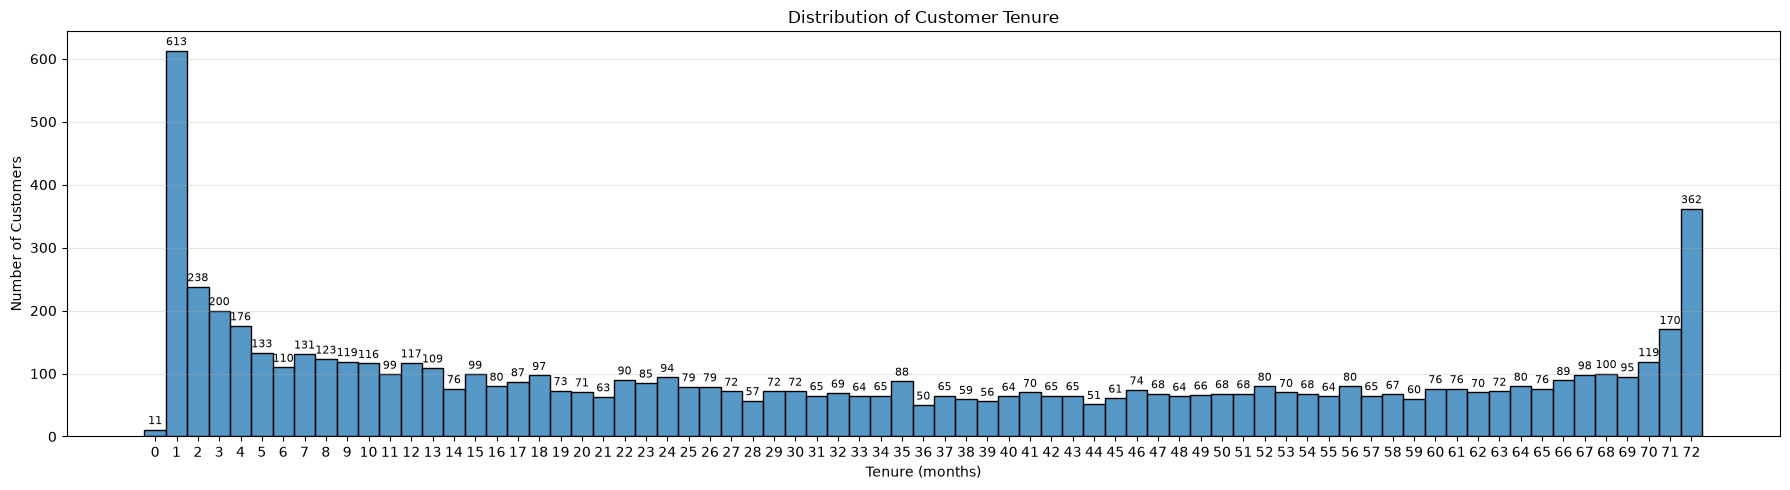

In [ ]:
# analysing the distribution of tenure - histogram

plt.figure(figsize=(18, 5))

ax = sns.histplot(
    data=df,
    x="tenure",
    bins=np.arange(-0.5, 73.5, 1)
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=2, fontsize=8)

plt.xticks(range(0, 73, 1))
plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

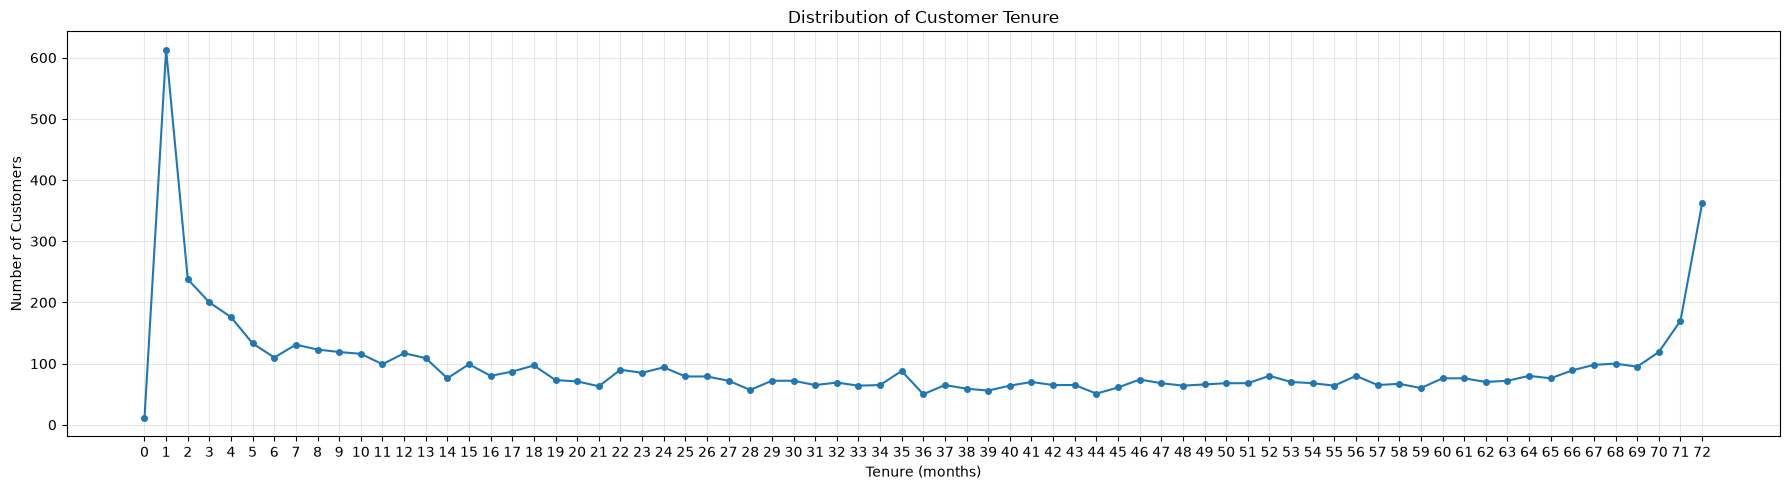

In [ ]:
# analyzing the distribution of tenure - line plot

tenure_counts = df["tenure"].value_counts().sort_index()

plt.figure(figsize=(18, 5))

plt.plot(
    tenure_counts.index,
    tenure_counts.values,
    marker="o",
    linestyle="-",
    markersize=4
)

plt.xticks(range(0, 73, 1))
plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of Customers")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [68]:
df["tenure"].value_counts().head(10)

tenure
1     613
72    362
2     238
3     200
4     176
71    170
5     133
7     131
8     123
70    119
Name: count, dtype: int64

In [72]:
df["tenure"].unique()

array([ 1, 34,  2, 45,  8, 22, 10, 28, 62, 13, 16, 58, 49, 25, 69, 52, 71,
       21, 12, 30, 47, 72, 17, 27,  5, 46, 11, 70, 63, 43, 15, 60, 18, 66,
        9,  3, 31, 50, 64, 56,  7, 42, 35, 48, 29, 65, 38, 68, 32, 55, 37,
       36, 41,  6,  4, 33, 67, 23, 57, 61, 14, 20, 53, 40, 59, 24, 44, 19,
       54, 51, 26,  0, 39])

In [73]:
'''
Observations from tenure distribution:
- The tenure of customers ranges from 0 to 72 months.
- The mean tenure is approximately 32.37 months, while the median is 29 months, indicating a slight right skew in the distribution (mode < median < mean).
- The mode of tenure is 1 month, suggesting that a significant number of customers have been with the company for only a short period.
- There is a noticeable drop in the number of customers after 12 months, which may indicate a higher churn rate among customers who 
  have been with the company for a year or less.
- The distribution shows a gradual decline in the number of customers as tenure increases, with a few peaks at certain tenure values,
'''

'\nObservations from tenure distribution:\n- The tenure of customers ranges from 0 to 72 months.\n- The mean tenure is approximately 32.37 months, while the median is 29 months, indicating a slight right skew in the distribution (mode < median < mean).\n- The mode of tenure is 1 month, suggesting that a significant number of customers have been with the company for only a short period.\n- There is a noticeable drop in the number of customers after 12 months, which may indicate a higher churn rate among customers who \n  have been with the company for a year or less.\n- The distribution shows a gradual decline in the number of customers as tenure increases, with a few peaks at certain tenure values,\n'

In [75]:
# analyzing the tenure and churn relationship

df.groupby('Churn')['tenure'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


In [76]:
''' 
Observations from tenure and churn relationship:
- Customers who have churned have a lower average tenure (mean = 17.9 months) compared to those who have not churned (mean = 37.69 months).
- The median tenure for churned customers is 9 months, while for non-churned it is 38 months, indicating that churned customers tend to leave 
  the company relatively early in their tenure.
- The standard deviation of tenure is higher for churned customers, suggesting more variance in the length of time they stay with the company.
- the average tenure for churned customer = 18 and median is 10 again right skewed which means more customers are leaving the company in the first 10 months of their tenure.

'''

' \nObservations from tenure and churn relationship:\n- Customers who have churned have a lower average tenure (mean = 17.9 months) compared to those who have not churned (mean = 37.69 months).\n- The median tenure for churned customers is 9 months, while for non-churned it is 38 months, indicating that churned customers tend to leave \n  the company relatively early in their tenure.\n- The standard deviation of tenure is higher for churned customers, suggesting more variance in the length of time they stay with the company.\n- the average tenure for churned customer = 18 and median is 10 again right skewed which means more customers are leaving the company in the first 10 months of their tenure.\n\n'

In [83]:
# calculating churn percentage by tenure

df.groupby("tenure")["Churn"].value_counts(normalize=True) * 100

tenure  Churn
0       No       100.000000
1       Yes       61.990212
        No        38.009788
2       Yes       51.680672
        No        48.319328
                    ...    
70      Yes        9.243697
71      No        96.470588
        Yes        3.529412
72      No        98.342541
        Yes        1.657459
Name: proportion, Length: 145, dtype: float64

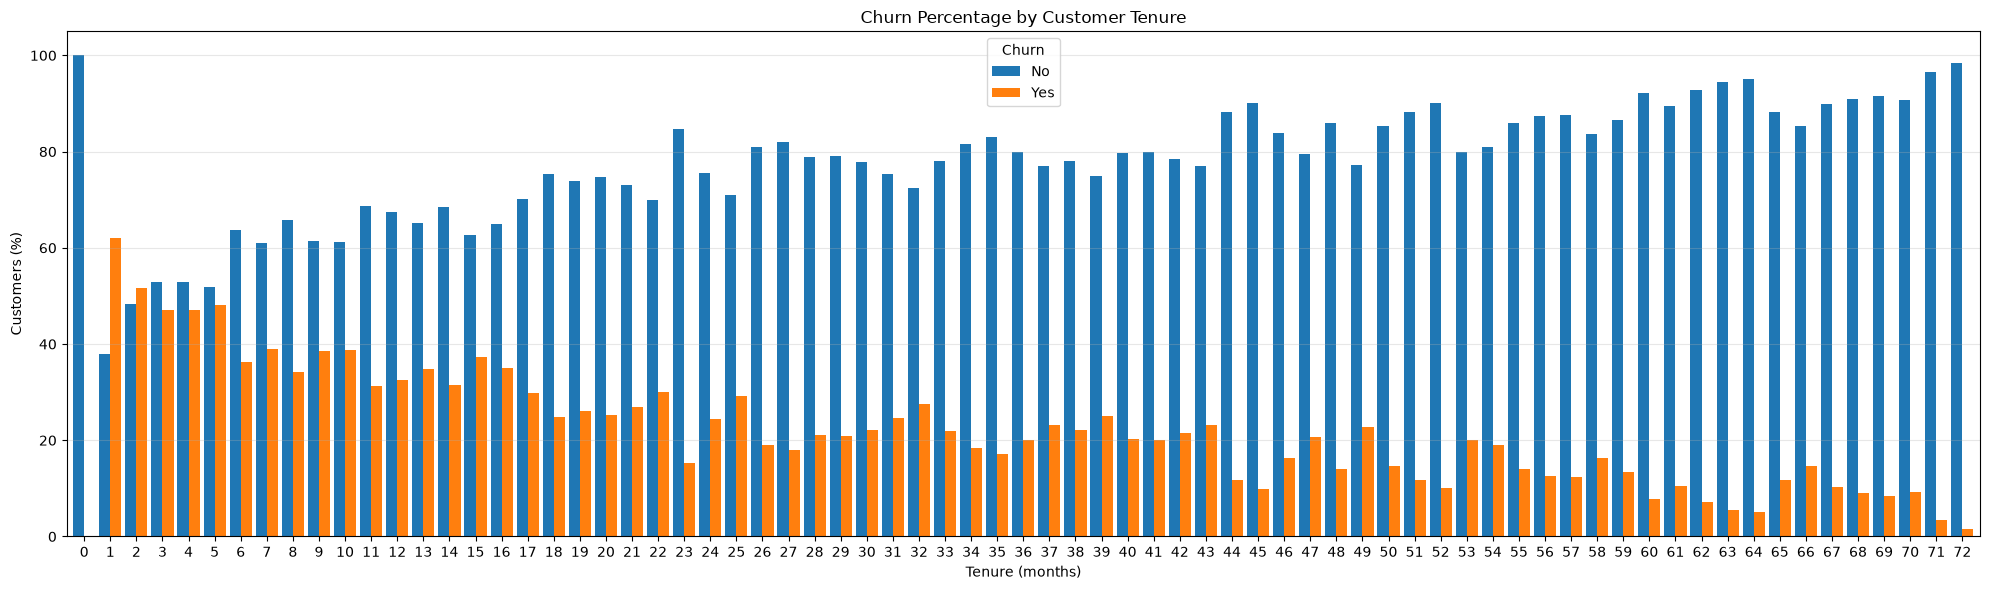

In [84]:
churn_percentages = (
    pd.crosstab(
        df["tenure"],
        df["Churn"],
        normalize="index"
    ) * 100
)

churn_percentages.plot(
    kind="bar",
    figsize=(20, 6),
    width=0.85
)

plt.title("Churn Percentage by Customer Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Customers (%)")
plt.xticks(range(0, 73, 1), rotation=0)
plt.legend(title="Churn")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [85]:
'''
Observations from churn percentage by tenure graph:

Churn percentages are considerably higher among customers with short tenures and generally lower among customers with long tenures.
For example, approximately 62% of customers with one month of tenure churned, compared with approximately 1.66% of customers with 72 months of tenure. 
The zero-month group contains only 11 customers so needs to be investigated further.
'''

'\nObservations from churn percentage by tenure graph:\n\nChurn percentages are considerably higher among customers with short tenures and generally lower among customers with long tenures.\nFor example, approximately 62% of customers with one month of tenure churned, compared with approximately 1.66% of customers with 72 months of tenure. \nThe zero-month group contains only 11 customers so needs to be investigated further.\n'

In [86]:
# analyse contract

df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [88]:
df['Contract'].value_counts(normalize=True) * 100

Contract
Month-to-month    55.019168
Two year          24.066449
One year          20.914383
Name: proportion, dtype: float64

In [89]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [91]:
''' 
Observations from contract type and churn relationship:
- Customers with month-to-month contracts have the highest churn rate (43.3%), while those with one-year contracts have a lower churn rate (11.3%), and those with two-year contracts have the lowest churn rate (5.3%). 
- This suggests that customers with longer-term contracts are less likely to churn, possibly due to the commitment and benefits associated with these contracts.
'''

' \nObservations from contract type and churn relationship:\n- Customers with month-to-month contracts have the highest churn rate (43.3%), while those with one-year contracts have a lower churn rate (11.3%), and those with two-year contracts have the lowest churn rate (5.3%). \n- This suggests that customers with longer-term contracts are less likely to churn, possibly due to the commitment and benefits associated with these contracts.\n'

In [93]:
# analysing contract and tenure relationship

df.groupby('Contract')['tenure'].describe()


,count,mean,std,min,25%,50%,75%,max
Contract,,,,,,,,
Month-to-month,3875.0,18.036645,17.689054,1.0,3.0,12.0,29.0,72.0
One year,1473.0,42.044807,19.035883,0.0,27.0,44.0,58.0,72.0
Two year,1695.0,56.735103,18.209363,0.0,48.0,64.0,71.0,72.0


In [95]:
'''

Observations from contract type and churn relationship:
- Customers with month-to-month contracts have the highest churn rate (43.3%), while those with one-year contracts have a lower churn rate (11.3%),
  and those with two-year contracts have the lowest churn rate (5.3%). 
- This suggests that customers with longer-term contracts are less likely to churn,
  possibly due to the commitment and benefits associated with these contracts.

'''

'\n\nObservations from contract type and churn relationship:\n- Customers with month-to-month contracts have the highest churn rate (43.3%), while those with one-year contracts have a lower churn rate (11.3%),\n  and those with two-year contracts have the lowest churn rate (5.3%). \n- This suggests that customers with longer-term contracts are less likely to churn,\n  possibly due to the commitment and benefits associated with these contracts.\n\n'

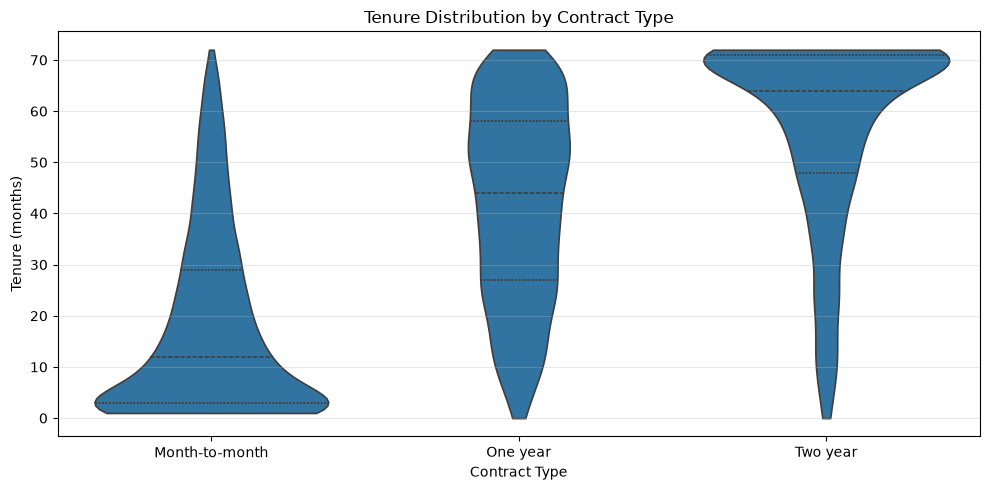

In [ ]:
# voilin plot to visualize the distribution of tenure for each contract type

plt.figure(figsize=(10, 5))

sns.violinplot(
    data=df,
    x='Contract',
    y='tenure',
    inner='quartile',
    cut=0
)

plt.title('Tenure Distribution by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Tenure (months)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


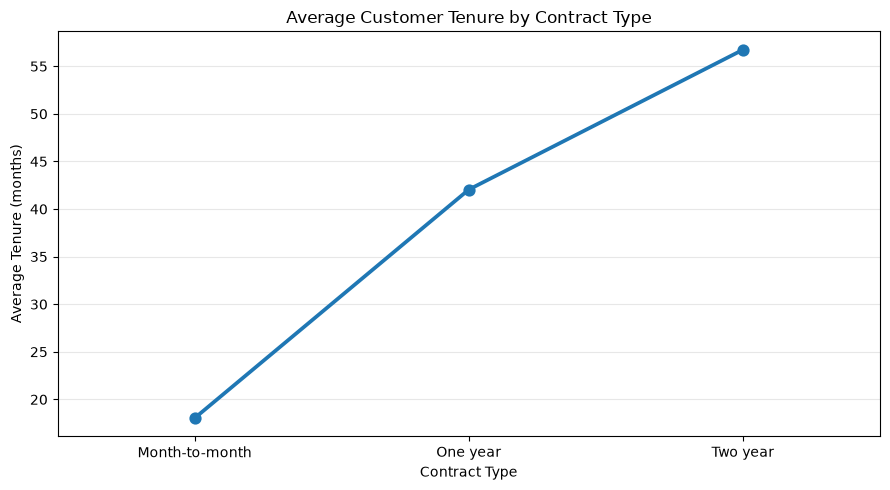

In [ ]:
# point plot to visualize the average tenure for each contract type

plt.figure(figsize=(9, 5))

sns.pointplot(
    data=df,
    x='Contract',
    y='tenure',
    errorbar=None
)

plt.title('Average Customer Tenure by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Average Tenure (months)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [100]:
# analyzing contract and monthly charges relationship

df.groupby('Contract')['MonthlyCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Contract,,,,,,,,
Month-to-month,3875.0,66.398490,26.926599,18.75,45.850,73.25,88.875,117.45
One year,1473.0,65.048608,31.840539,18.25,26.900,68.75,94.800,118.60
Two year,1695.0,60.770413,34.678865,18.40,24.025,64.35,90.450,118.75


In [101]:
''' 

Observations from contract type and monthly charges relationship:

- Month-to-month customers have the highest mean monthly charges (66.40), followed by one-year (65.05) and two-year customers (60.77).
- Median monthly charges follow the same pattern: 73.25, 68.75, and 64.35, respectively.
- The standard deviation of monthly charges is highest among two-year contract customers (34.68) and lowest among month-to-month customers (26.93).
- Monthly charges show variation within all three contract groups.
- Contract type is associated with differences in monthly charges, but this analysis does not establish that contract duration causes those differences.

Conclusion: 
Month-to-month customers pay somewhat higher monthly charges on average in this dataset. Monthly charges may be worth investigating alongside 
contract type and tenure when analyzing churn.

'''

' \n\nObservations from contract type and monthly charges relationship:\n\n- Month-to-month customers have the highest mean monthly charges (66.40), followed by one-year (65.05) and two-year customers (60.77).\n- Median monthly charges follow the same pattern: 73.25, 68.75, and 64.35, respectively.\n- The standard deviation of monthly charges is highest among two-year contract customers (34.68) and lowest among month-to-month customers (26.93).\n- Monthly charges show variation within all three contract groups.\n- Contract type is associated with differences in monthly charges, but this analysis does not establish that contract duration causes those differences.\n\nConclusion: \nMonth-to-month customers pay somewhat higher monthly charges on average in this dataset. Monthly charges may be worth investigating alongside \ncontract type and tenure when analyzing churn.\n\n'

In [102]:
tenure_contract_churn = (
    df.assign(Churned=(df['Churn'] == 'Yes').astype(int))
      .groupby(['tenure', 'Contract'])['Churned']
      .mean()
      .mul(100)
      .reset_index(name='ChurnRate')
)

tenure_contract_churn.head(10)

,tenure,Contract,ChurnRate
0,0,One year,0.000000
1,0,Two year,0.000000
2,1,Month-to-month,62.913907
3,1,One year,0.000000
4,1,Two year,0.000000
5,2,Month-to-month,52.608696
6,2,One year,28.571429
7,2,Two year,0.000000
8,3,Month-to-month,49.214660
9,3,One year,0.000000


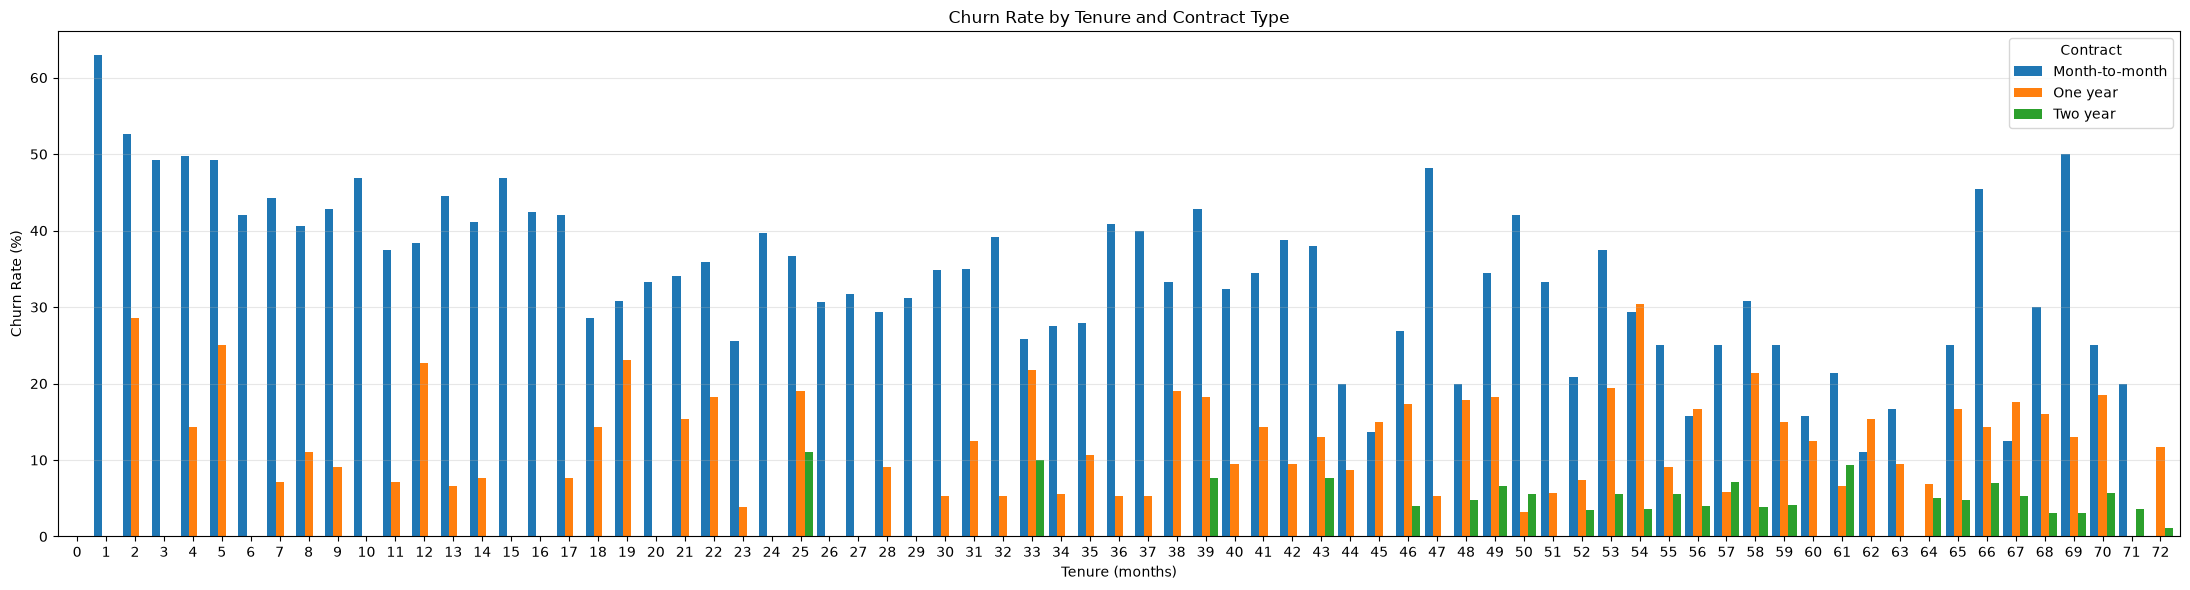

In [104]:
churn_pivot = tenure_contract_churn.pivot(
    index='tenure',
    columns='Contract',
    values='ChurnRate'
)

churn_pivot.plot(
    kind='bar',
    figsize=(22, 6),
    width=0.85
)

plt.title('Churn Rate by Tenure and Contract Type')
plt.xlabel('Tenure (months)')
plt.ylabel('Churn Rate (%)')
plt.xticks(range(0, 73, 1), rotation=0)
plt.legend(title='Contract')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [105]:
''' 

Observations from churn rate by tenure and contract type:

- Month-to-month customers have the highest churn rate across all tenures.
- One-year customers show a moderate churn rate, while two-year customers have the lowest churn rate.
- The churn rate tends to decrease as tenure increases for all contract types.
- Contract type is associated with differences in churn rates, but this analysis does not establish that contract duration causes those differences.

Conclusion: 
Contract type is a significant factor in predicting customer churn. Month-to-month customers are more likely to churn compared to those on longer-term contracts. Understanding the relationship between contract type, tenure, and churn can help in developing targeted retention strategies.

'''

' \n\nObservations from churn rate by tenure and contract type:\n\n- Month-to-month customers have the highest churn rate across all tenures.\n- One-year customers show a moderate churn rate, while two-year customers have the lowest churn rate.\n- The churn rate tends to decrease as tenure increases for all contract types.\n- Contract type is associated with differences in churn rates, but this analysis does not establish that contract duration causes those differences.\n\nConclusion: \nContract type is a significant factor in predicting customer churn. Month-to-month customers are more likely to churn compared to those on longer-term contracts. Understanding the relationship between contract type, tenure, and churn can help in developing targeted retention strategies.\n\n'

In [ ]:
# Observing Tenure, Contract and Churn

group_sizes = df.groupby(['tenure', 'Contract']).size()

group_sizes.describe()

count    218.000000
mean      32.307339
std       53.858511
min        1.000000
25%       11.000000
50%       20.500000
75%       31.000000
max      604.000000
dtype: float64

In [107]:
tenure_contract_summary = (
    df.assign(Churned=(df['Churn'] == 'Yes').astype(int))
      .groupby(['tenure', 'Contract'])
      .agg(
          Customers=('Churned', 'size'),
          ChurnRate=('Churned', 'mean')
      )
      .assign(ChurnRate=lambda x: x['ChurnRate'] * 100)
      .reset_index()
)

tenure_contract_summary.head(10)

,tenure,Contract,Customers,ChurnRate
0,0,One year,1,0.000000
1,0,Two year,10,0.000000
2,1,Month-to-month,604,62.913907
3,1,One year,7,0.000000
4,1,Two year,2,0.000000
5,2,Month-to-month,230,52.608696
6,2,One year,7,28.571429
7,2,Two year,1,0.000000
8,3,Month-to-month,191,49.214660
9,3,One year,6,0.000000


In [108]:
reliable_groups = tenure_contract_summary[
    tenure_contract_summary['Customers'] >= 20
]

reliable_groups.head(10)

,tenure,Contract,Customers,ChurnRate
2,1,Month-to-month,604,62.913907
5,2,Month-to-month,230,52.608696
8,3,Month-to-month,191,49.214660
11,4,Month-to-month,165,49.696970
14,5,Month-to-month,128,49.218750
17,6,Month-to-month,95,42.105263
20,7,Month-to-month,113,44.247788
23,8,Month-to-month,101,40.594059
26,9,Month-to-month,105,42.857143
29,10,Month-to-month,96,46.875000


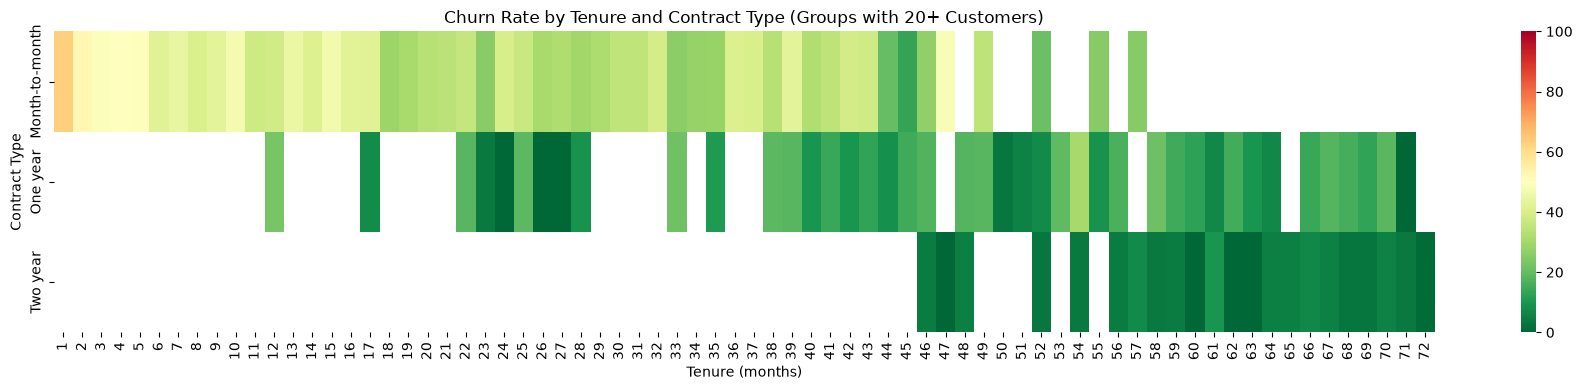

In [109]:
heatmap_data = reliable_groups.pivot(
    index='Contract',
    columns='tenure',
    values='ChurnRate'
)

plt.figure(figsize=(18, 4))

sns.heatmap(
    heatmap_data,
    annot=False,
    cmap='RdYlGn_r',
    vmin=0,
    vmax=100
)

plt.title('Churn Rate by Tenure and Contract Type (Groups with 20+ Customers)')
plt.xlabel('Tenure (months)')
plt.ylabel('Contract Type')
plt.tight_layout()
plt.show()

In [113]:
# analyzing monthly charges

df['MonthlyCharges'].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

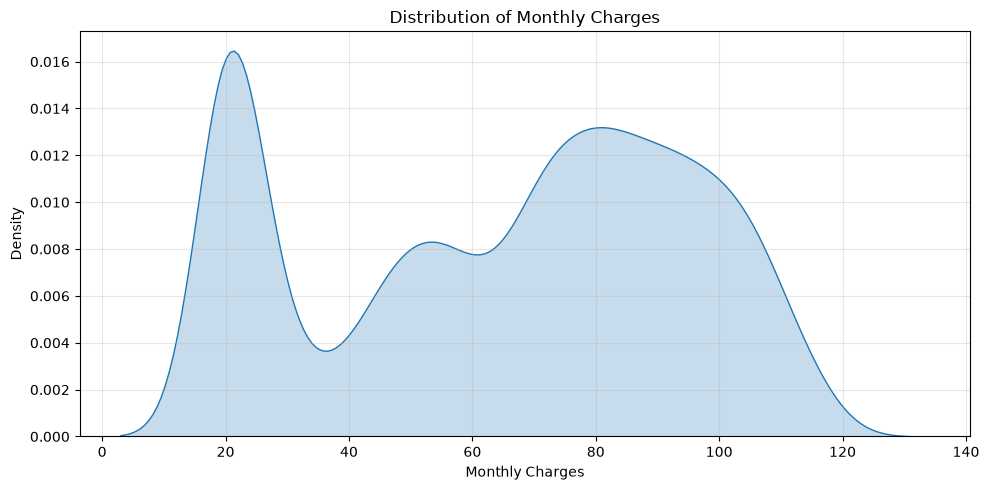

In [119]:
plt.figure(figsize=(10, 5))

sns.kdeplot(data=df, x='MonthlyCharges', fill=True)

plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges')
plt.ylabel('Density')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

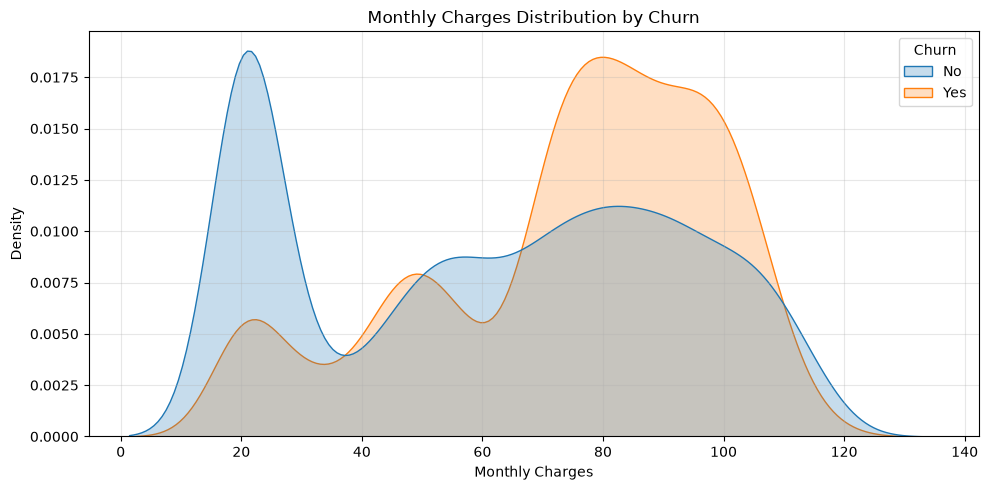

In [121]:
# customers who churn pay different monthly charges from customers who stay

plt.figure(figsize=(10, 5))

sns.kdeplot(
    data=df,
    x='MonthlyCharges',
    hue='Churn',
    fill=True,
    common_norm=False
)

plt.title('Monthly Charges Distribution by Churn')
plt.xlabel('Monthly Charges')
plt.ylabel('Density')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [122]:
# calculate the actual churn rate by charge range

df['ChargeRange'] = pd.cut(
    df['MonthlyCharges'],
    bins=[0, 30, 50, 70, 90, 120],
    labels=['0-30', '30-50', '50-70', '70-90', '90-120']
)

charge_churn = (
    pd.crosstab(df['ChargeRange'], df['Churn'], normalize='index') * 100
)

charge_churn

Churn,No,Yes
ChargeRange,,
0-30,90.199637,9.800363
30-50,69.195046,30.804954
50-70,79.242033,20.757967
70-90,62.201735,37.798265
90-120,67.222542,32.777458


In [124]:
# check the number of customers in each range

charge_churn_summary = (
    df.groupby('ChargeRange', observed=False)
      .agg(
          Customers=('Churn', 'size'),
          ChurnRate=('Churn', lambda x: (x == 'Yes').mean() * 100)
      )
)

charge_churn_summary

,Customers,ChurnRate
ChargeRange,,
0-30,1653,9.800363
30-50,646,30.804954
50-70,1161,20.757967
70-90,1844,37.798265
90-120,1739,32.777458


In [125]:
''' 
Observations from tenure and churn relationship:
- Customers who have churned have a lower average tenure (mean = 16.37 months) compared to those who have not churned (mean = 37.69 months).
- The median tenure for churned customers is 9 months, while for non-churned customers it is 38 months, indicating that churned customers 
  tend to leave the company relatively early in their tenure.

'''

' \nObservations from tenure and churn relationship:\n- Customers who have churned have a lower average tenure (mean = 16.37 months) compared to those who have not churned (mean = 37.69 months).\n- The median tenure for churned customers is 9 months, while for non-churned customers it is 38 months, indicating that churned customers \n  tend to leave the company relatively early in their tenure.\n\n'

In [126]:
# exploring total charges

df['TotalCharges'].describe()

count     7043
unique    6539
top       20.2
freq        11
Name: TotalCharges, dtype: object

In [ ]:
# checking missing values in TotalCharges column
df['TotalCharges'].isna().sum(), (df['TotalCharges'].str.strip() == '').sum()

(np.int64(0), np.int64(11))

In [ ]:
# checking for rows with empty TotalCharges values

df.loc[
    df['TotalCharges'].str.strip() == '',
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
1218,2923-ARZLG,0,19.70,,No
2670,4075-WKNIU,0,73.35,,No
2754,2775-SEFEE,0,61.90,,No
3296,3115-CZMZD,0,20.25,,No
3479,5709-LVOEQ,0,80.85,,No
3625,4367-NUYAO,0,25.75,,No
3883,1371-DWPAZ,0,56.05,,No
5874,7644-OMVMY,0,19.85,,No
6369,3213-VVOLG,0,25.35,,No


In [ ]:
# converting TotalCharges to numeric, coercing errors to NaN for empty strings

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].str.strip(),
    errors='coerce'
)

In [130]:
df['TotalCharges'].dtype

dtype('float64')

In [131]:
df['TotalCharges'].isna().sum()

np.int64(11)

In [132]:
df['TotalCharges'].describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64